# FedAdam con MNIST

Entrenamiento con cuatro grupos y la CNN de `model.py`.
Los grupos usan SGD y el servidor actualiza el modelo global con FedAdam.

Referencia: [Adaptive Federated Optimization](https://arxiv.org/abs/2003.00295), algoritmo 2.

In [28]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from model import build_model

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

NUM_GRUPOS = 4
ROUNDS = 5
LOCAL_EPOCHS = 1
GRUPO_LR = 0.02
SERVER_LR = 0.01
BETA_1 = 0.9
BETA_2 = 0.99
TAU = 1e-3
OUTPUT_DIR = Path("artifacts_fedadam")


TensorFlow: 2.21.0
GPU: []


## Datos

Separamos el 10% para validacion y repartimos el resto entre cuatro grupos.
El conjunto de prueba se usa al final.

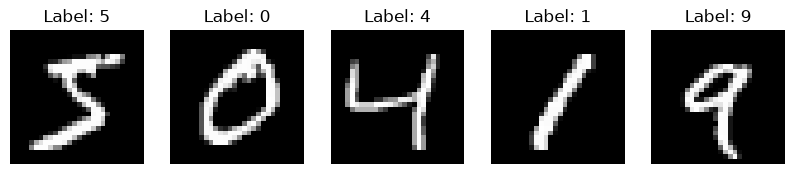

Grupo 1: 13500 ejemplos
Frecuencia de numeros: {0: 1333, 1: 1517, 2: 1341, 3: 1380, 4: 1314, 5: 1220, 6: 1332, 7: 1409, 8: 1316, 9: 1338}
Primeros ejemplos (labels): [2, 1, 5, 1, 8, 0, 8, 7, 1, 1, 7, 5, 1, 8, 5]
Grupo 2: 13500 ejemplos
Frecuencia de numeros: {0: 1333, 1: 1517, 2: 1341, 3: 1380, 4: 1314, 5: 1219, 6: 1332, 7: 1409, 8: 1317, 9: 1338}
Primeros ejemplos (labels): [8, 7, 8, 7, 7, 8, 7, 7, 7, 7, 7, 7, 8, 7, 7]
Grupo 3: 13500 ejemplos
Frecuencia de numeros: {0: 1332, 1: 1517, 2: 1340, 3: 1379, 4: 1315, 5: 1220, 6: 1331, 7: 1410, 8: 1317, 9: 1339}
Primeros ejemplos (labels): [7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 9, 7, 7, 9, 7]
Grupo 4: 13500 ejemplos
Frecuencia de numeros: {0: 1333, 1: 1517, 2: 1340, 3: 1379, 4: 1315, 5: 1220, 6: 1331, 7: 1410, 8: 1316, 9: 1339}
Primeros ejemplos (labels): [7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7]
Validacion: 6000 | Prueba final: 10000


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
train, test = tf.keras.datasets.mnist.load_data()

x_train = np.expand_dims(train[0].astype("float32") / 255.0, -1)
x_test = np.expand_dims(test[0].astype("float32") / 255.0, -1)
y_train, y_test = train[1], test[1]

plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i, :, :, 0], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train, test_size=0.1, stratify=y_train, random_state=SEED,
)

skf = StratifiedKFold(n_splits=NUM_GRUPOS)
folds = skf.split(x_train, y_train)
datos_grupos = [(x_train[tsix], y_train[tsix]) for _, tsix in folds]

for grupo_id, (_, labels) in enumerate(datos_grupos, start=1):
    print(f"Grupo {grupo_id}: {len(labels)} ejemplos")
    print("Frecuencia de numeros:", {int(numero): int(cantidad) for numero, cantidad in zip(*np.unique(labels, return_counts=True))})
    print("Primeros ejemplos (labels):", labels[:15].tolist())
print(f"Validacion: {len(y_val)} | Prueba final: {len(y_test)}")
build_model().summary()


## Funciones de entrenamiento

Cada grupo devuelve la diferencia entre sus pesos entrenados y los globales.
FedAdam usa el promedio de esos cambios y conserva los momentos `m` y `v` entre rondas.
Usamos la variante sin correccion de sesgo, con `m = 0` y `v = TAU ** 2` al inicio.

In [30]:
def entrenar_grupo(global_weights, datos_grupo):
    # Todos los grupos parten de los mismos pesos.
    modelo_grupo = build_model(learning_rate=GRUPO_LR, optimizer="sgd")
    modelo_grupo.set_weights(global_weights)
    x_grupo, y_grupo = datos_grupo

    history = modelo_grupo.fit(
        x_grupo, y_grupo, epochs=LOCAL_EPOCHS,
        validation_data=(x_val, y_val),
        shuffle=True, verbose=0,
    )

    # Cambios respecto al modelo global.
    delta = [
        local - global_w
        for local, global_w in zip(modelo_grupo.get_weights(), global_weights)
    ]
    return delta, len(y_grupo), history.history


def actualizar_fedadam(global_weights, mean_delta, m, v):
    # Primer y segundo momento de los cambios.
    m = [BETA_1 * anterior + (1 - BETA_1) * delta
         for anterior, delta in zip(m, mean_delta)]
    v = [BETA_2 * anterior + (1 - BETA_2) * delta ** 2
         for anterior, delta in zip(v, mean_delta)]

    nuevos_pesos = [
        w + SERVER_LR * momento / (np.sqrt(varianza) + TAU)
        for w, momento, varianza in zip(global_weights, m, v)
    ]
    return nuevos_pesos, m, v


def graficar_curvas(history, pasos, titulo, eje_x):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metrica, etiqueta in zip(axes, ["accuracy", "loss"], ["Accuracy", "Perdida"]):
        ax.plot(pasos, history[metrica], marker="o", label="Entrenamiento")
        ax.plot(pasos, history["val_" + metrica], marker="o", label="Validacion")
        ax.set(xlabel=eje_x, ylabel=etiqueta, title=f"{titulo}: {etiqueta}")
        ax.legend()
    plt.tight_layout()
    plt.show()


## Entrenamiento

In [31]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
global_model = build_model()

# Los momentos se conservan entre rondas.
m = [np.zeros_like(w) for w in global_model.get_weights()]
v = [np.full_like(w, TAU ** 2) for w in global_model.get_weights()]

total_examples = sum(len(labels) for _, labels in datos_grupos)
metricas = ["loss", "accuracy", "val_loss", "val_accuracy"]

history = {metrica: [] for metrica in metricas}
history["round"] = []
historial_grupos = {
    grupo_id: {metrica: [] for metrica in metricas}
    for grupo_id in range(1, NUM_GRUPOS + 1)
}

for round_number in range(1, ROUNDS + 1):
    # Pesos que recibiran los cuatro grupos.
    global_weights = global_model.get_weights()
    mean_delta = [np.zeros_like(w) for w in global_weights]

    for grupo_id, datos_grupo in enumerate(datos_grupos, start=1):
        delta, num_examples, historial_local = entrenar_grupo(global_weights, datos_grupo)
        for metrica in metricas:
            historial_grupos[grupo_id][metrica].extend(historial_local[metrica])

        # Promedio ponderado por el numero de ejemplos de cada grupo.
        proporcion = num_examples / total_examples
        for k, cambio in enumerate(delta):
            mean_delta[k] += proporcion * cambio
        print(f"  Ronda {round_number}: grupo {grupo_id} completado")

    # Actualizacion global con FedAdam.
    nuevos_pesos, m, v = actualizar_fedadam(global_weights, mean_delta, m, v)
    global_model.set_weights(nuevos_pesos)

    # Evaluamos modelo  para construir sus curvas.
    train_loss, train_accuracy = global_model.evaluate(x_train, y_train, verbose=0)
    val_loss, val_accuracy = global_model.evaluate(x_val, y_val, verbose=0)
    history["round"].append(round_number)
    history["loss"].append(float(train_loss))
    history["accuracy"].append(float(train_accuracy))
    history["val_loss"].append(float(val_loss))
    history["val_accuracy"].append(float(val_accuracy))
    print(f"Ronda {round_number}/{ROUNDS} | accuracy={train_accuracy:.4f} "
          f"| val_loss={val_loss:.4f} "
          f"| val_accuracy={val_accuracy:.4f}")


  Ronda 1: grupo 1 completado
  Ronda 1: grupo 2 completado
  Ronda 1: grupo 3 completado
  Ronda 1: grupo 4 completado
Ronda 1/5 | accuracy=0.6188 | val_loss=2.0599 | val_accuracy=0.6137
  Ronda 2: grupo 1 completado
  Ronda 2: grupo 2 completado
  Ronda 2: grupo 3 completado
  Ronda 2: grupo 4 completado
Ronda 2/5 | accuracy=0.8948 | val_loss=1.2897 | val_accuracy=0.8892
  Ronda 3: grupo 1 completado
  Ronda 3: grupo 2 completado
  Ronda 3: grupo 3 completado
  Ronda 3: grupo 4 completado
Ronda 3/5 | accuracy=0.9237 | val_loss=0.4550 | val_accuracy=0.9232
  Ronda 4: grupo 1 completado
  Ronda 4: grupo 2 completado
  Ronda 4: grupo 3 completado
  Ronda 4: grupo 4 completado
Ronda 4/5 | accuracy=0.9353 | val_loss=0.2237 | val_accuracy=0.9355
  Ronda 5: grupo 1 completado
  Ronda 5: grupo 2 completado
  Ronda 5: grupo 3 completado
  Ronda 5: grupo 4 completado
Ronda 5/5 | accuracy=0.9446 | val_loss=0.2199 | val_accuracy=0.9433


## Curvas por grupo


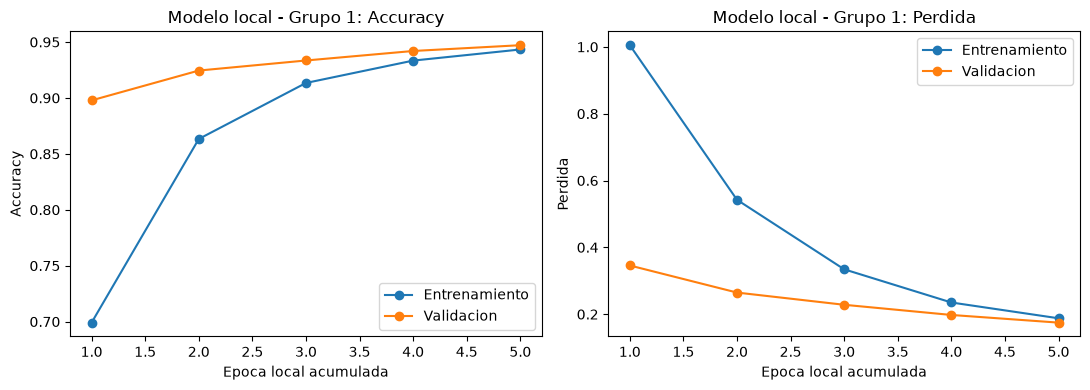

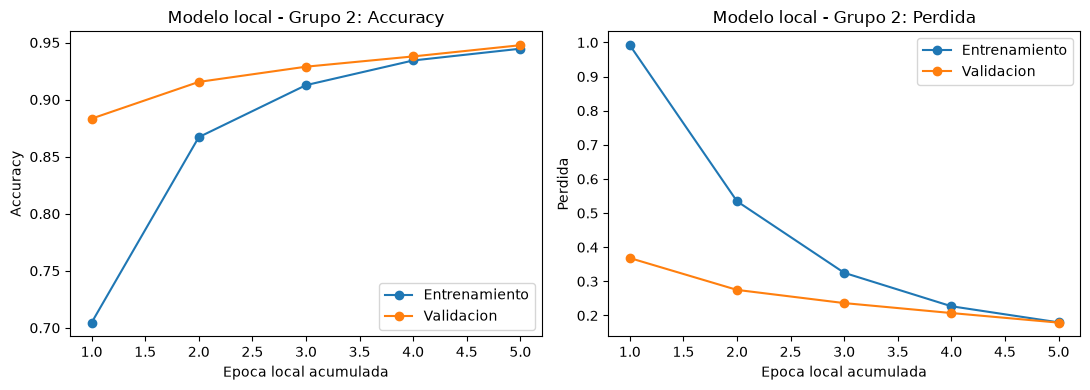

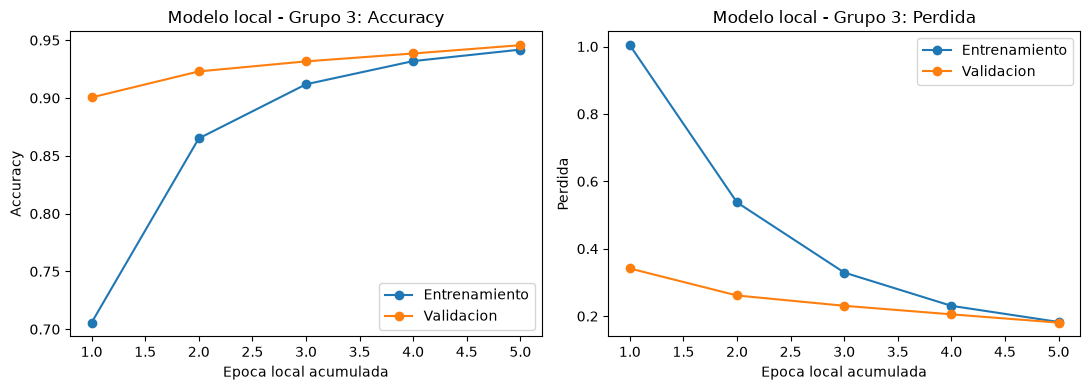

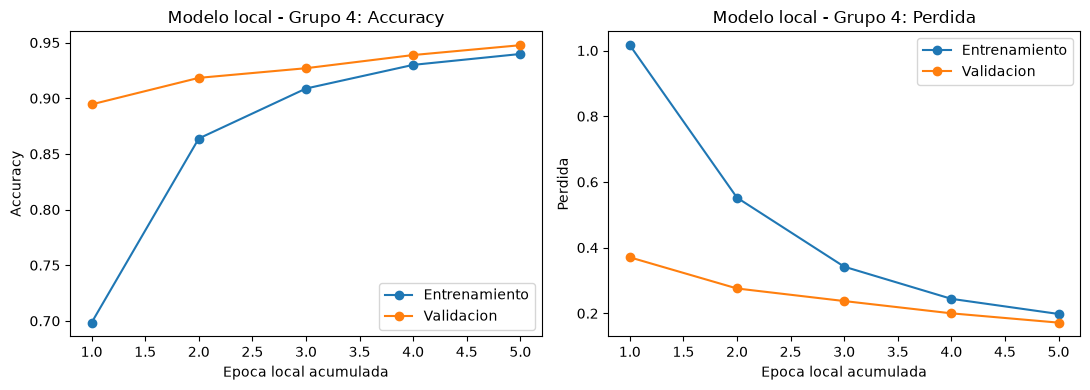

In [32]:
for grupo_id, historial_local in historial_grupos.items():
    epocas = range(1, len(historial_local["loss"]) + 1)
    graficar_curvas(
        historial_local, epocas, f"Modelo local - Grupo {grupo_id}",
        "Epoca local acumulada",
    )


## Modelo global

Evaluacion en prueba, curvas por ronda y guardado del modelo y los historiales.
Para retomar el entrenamiento federado tambien haria falta guardar `m` y `v`.

Prueba final | loss=0.1838 | accuracy=0.9493
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       980
           1       0.97      0.99      0.98      1135
           2       0.94      0.95      0.94      1032
           3       0.93      0.95      0.94      1010
           4       0.96      0.96      0.96       982
           5       0.93      0.96      0.94       892
           6       0.97      0.95      0.96       958
           7       0.92      0.95      0.94      1028
           8       0.95      0.92      0.94       974
           9       0.96      0.88      0.92      1009

    accuracy                           0.95     10000
   macro avg       0.95      0.95      0.95     10000
weighted avg       0.95      0.95      0.95     10000



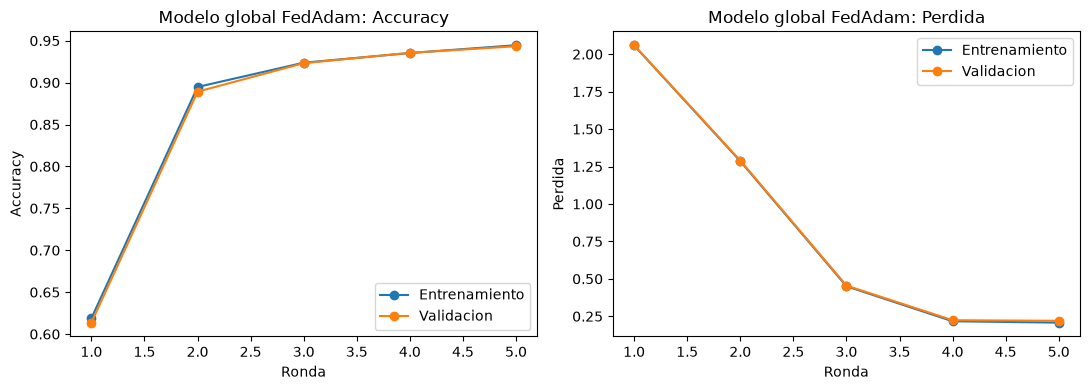

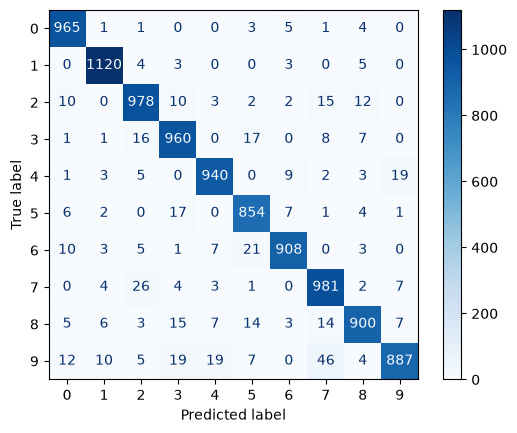

In [33]:
test_loss, test_accuracy = global_model.evaluate(x_test, y_test, verbose=0)
y_pred = np.argmax(global_model.predict(x_test, verbose=0), axis=1)
print(f"Prueba final | loss={test_loss:.4f} | accuracy={test_accuracy:.4f}")
print(classification_report(y_test, y_pred, labels=np.arange(10), zero_division=0))

graficar_curvas(history, history["round"], "Modelo global FedAdam", "Ronda")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.show()
